# Thesis Experiment Figures

Load aggregated CSV files produced by the synthetic experiment scripts and create reconstruction and clustering figures. Run the synthetic experiment suite first if the required files are not already under `results/reconstruction/` and `results/clustering/`. The plotting styles are configured for thesis figures.

In [3]:
# Publication-quality figure settings
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'font.size': 12,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 11,
})


In [15]:
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 11,
})

import os
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# --- PATH CONFIGURATION ---
REC_DIR = "results/reconstruction"
CLUS_DIR = "results/clustering"

# --- LABEL MAPPINGS ---
METHOD_MAPPING = {
    "proposed": "Proposed Method",
    "iterative": "Iterative",
    "oracle": "Proposed (True Assignment)",
    "basic_psd": "Global PSD",
    "smoothing": "Smoothness-based",
    "global_psd_spline": "Global PSD",
    "simultaneous": "Simultaneous"
}

TOPOLOGY_MAPPING = {
    "barabasi_albert": "Barabási-Albert",
    "erdos_renyi": "Erdős-Rényi",
    "grid": "Grid",
    "knn": "k-NN",
    "watts_strogatz": "Watts-Strogatz"
}

def apply_mapping(df):
    """Map internal method and topology names to publication-friendly labels."""
    df_mapped = df.copy()
    if 'method' in df_mapped.columns:
        df_mapped['method'] = df_mapped['method'].map(lambda x: METHOD_MAPPING.get(x, x))
    if 'topology' in df_mapped.columns:
        df_mapped['topology'] = df_mapped['topology'].map(lambda x: TOPOLOGY_MAPPING.get(x, x))
    return df_mapped

# --- GENERIC PLOTTING FUNCTIONS ---
# Figure size is chosen to fill the text width in a thesis.
FIG_SIZE_SINGLE = (12.0, 7.0)

def add_bottom_legend(ax, handles=None, labels=None, title=None, ncol=1):
    """Add a compact legend inside the upper-right corner of the plot."""
    if handles is not None and labels is not None:
        ax.legend(
            handles, labels,
            loc="upper right",
            frameon=True,
            framealpha=0.9,
            ncol=ncol,
            fontsize=11,
            title=title,
        )
    else:
        ax.legend(
            loc="upper right",
            frameon=True,
            framealpha=0.9,
            ncol=ncol,
            fontsize=11,
            title=title,
        )

# -- 1. SINGLE PLOTS (RECONSTRUCTION) --

def plot_line_filled(data, x_col, hue_col, title, xlabel, metric="mae", palette="Set2"):
    if data.empty: return
    sns.set_theme(style="whitegrid", palette=palette, font_scale=1.1)
    colors = sns.color_palette(palette, n_colors=10)
    
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)
    methods = data[hue_col].unique()
    std_col = f'std_{metric}'
    has_std = std_col in data.columns
    
    for i, method in enumerate(methods):
        subset = data[data[hue_col] == method].sort_values(x_col)
        ax.plot(subset[x_col], subset[metric], label=method, color=colors[i], marker="o", markersize=6, linewidth=2.0)
        
        if has_std:
            ax.fill_between(subset[x_col], subset[metric] - subset[std_col], 
                             subset[metric] + subset[std_col], color=colors[i], alpha=0.2)
            
    ax.set_title(title, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel, fontweight='bold')
    ax.set_ylabel(metric.upper(), fontweight='bold')
    
    x_ticks = sorted(data[x_col].unique())
    if len(x_ticks) > 0 and np.issubdtype(np.asarray(x_ticks).dtype, np.number):
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{x:g}" for x in x_ticks])
    
    # Add legend
    add_bottom_legend(ax, title="Method", ncol=3)
    
    # Reserve space for the figure elements
    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.18, top=0.90)
    plt.show()

def plot_bar_whiskers(data, x_col, hue_col=None, title="", xlabel="", metric="mae", palette="Set2"):
    if data.empty: return
    sns.set_theme(style="whitegrid", palette=palette, font_scale=1.1)
    colors = sns.color_palette(palette, n_colors=10)
    
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)
    categories = data[x_col].unique()
    x = np.arange(len(categories))
    std_col = f'std_{metric}'
    has_std = std_col in data.columns
    
    if hue_col:
        methods = data[hue_col].unique()
        width = 0.8 / len(methods)
        for i, method in enumerate(methods):
            subset = data[data[hue_col] == method].set_index(x_col).reindex(categories).reset_index()
            offset = (i - len(methods) / 2 + 0.5) * width
            yerr = subset[std_col] if has_std else None
            ax.bar(x + offset, subset[metric], width=width, label=method, color=colors[i], 
                    yerr=yerr, capsize=4, edgecolor='none', alpha=0.9)
            
        add_bottom_legend(ax, title="Method", ncol=3)
    else:
        subset = data.set_index(x_col).reindex(categories).reset_index()
        yerr = subset[std_col] if has_std else None
        ax.bar(x, subset[metric], width=0.6, color=colors[:len(categories)], 
                yerr=yerr, capsize=4, edgecolor='none', alpha=0.9)
            
    ax.set_title(title, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel, fontweight='bold')
    ax.set_ylabel(metric.upper(), fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=15 if len(categories) > 3 else 0)
    
    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.18 if hue_col else 0.12, top=0.90)
    plt.show()



# -- 1b. POINT PLOTS WITH ERROR BARS (RECONSTRUCTION) --

def plot_bar_filled(data, x_col, hue_col, title, xlabel,
                    metric="mae", palette="Set2"):
    """Plot grouped bars with mean values and standard-deviation ranges."""
    if data.empty:
        return

    sns.set_theme(style="whitegrid", palette=palette, font_scale=1.1)

    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)

    categories = list(data[x_col].dropna().unique())
    methods = list(data[hue_col].dropna().unique())

    x = np.arange(len(categories))
    width = 0.8 / len(methods)

    colors = sns.color_palette(palette, n_colors=len(methods))

    std_col = f"std_{metric}"
    has_std = std_col in data.columns

    for i, method in enumerate(methods):

        subset = (
            data[data[hue_col] == method]
            .set_index(x_col)
            .reindex(categories)
            .reset_index()
        )

        values = pd.to_numeric(
            subset[metric],
            errors="coerce"
        ).to_numpy()

        if has_std:
            errors = pd.to_numeric(
                subset[std_col],
                errors="coerce"
            ).to_numpy()
        else:
            errors = np.zeros_like(values)

        positions = (
            x
            + (i - (len(methods) - 1) / 2) * width
        )

        ax.bar(
            positions,
            values,
            width=width * 0.85,
            color=colors[i],
            alpha=0.85,
            edgecolor="none",
            label=method,
        )

        # Standard-deviation range
        ax.vlines(
            positions,
            values - errors,
            values + errors,
            color=colors[i],
            linewidth=2,
            alpha=0.9,
        )

        ax.scatter(
            positions,
            values,
            color=colors[i],
            s=25,
            zorder=3,
        )

        # Small horizontal caps
        cap_width = width * 0.25

        ax.hlines(
            values + errors,
            positions - cap_width / 2,
            positions + cap_width / 2,
            color=colors[i],
            linewidth=2,
        )

        ax.hlines(
            values - errors,
            positions - cap_width / 2,
            positions + cap_width / 2,
            color=colors[i],
            linewidth=2,
        )

    ax.set_title(
        title,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        xlabel,
        fontweight="bold"
    )

    ax.set_ylabel(
        metric.upper(),
        fontweight="bold"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(categories)

    ax.legend(
        loc="upper right",
        frameon=True,
        framealpha=0.9,
        fontsize=11,
        title="Method",
    )

    ax.grid(
        axis="y",
        alpha=0.35
    )

    ax.set_axisbelow(True)

    fig.subplots_adjust(
        left=0.09,
        right=0.98,
        bottom=0.12,
        top=0.90,
    )

    plt.show()

# -- 2. COMBINED PLOTS (CLUSTERING: ARI + ACCURACY) --

# -- 2. COMBINED PLOTS (CLUSTERING: ARI + ACCURACY) --

def plot_combined_clustering_line(data, x_col, hue_col, title, xlabel, palette="Dark2"):
    if data.empty: return
    sns.set_theme(style="whitegrid", font_scale=1.1)
    
    methods = list(data[hue_col].dropna().unique())
    colors = sns.color_palette(palette, n_colors=max(len(methods), 1))
    
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)
    x_ticks = sorted(data[x_col].dropna().unique())
    
    legend_elements = []
    
    for i, method in enumerate(methods):
        subset = data[data[hue_col] == method].sort_values(x_col)
        
# Accuracy: solid line with circle markers.
        ax.plot(subset[x_col], subset['clustering_accuracy'], color=colors[i], 
                marker="o", markersize=6, linestyle="-", linewidth=2.0)
        
# ARI: dashed line with square markers.
        ax.plot(subset[x_col], subset['ari'], color=colors[i], 
                marker="s", markersize=6, linestyle="--", linewidth=2.0)
        
# Build legend entries that match each metric's color, line style, and marker.
        legend_elements.append(Line2D([0], [0], color=colors[i], lw=2.0, linestyle="-", 
                                      marker="o", markersize=6, label=f"{method} – Accuracy"))
        legend_elements.append(Line2D([0], [0], color=colors[i], lw=2.0, linestyle="--", 
                                      marker="s", markersize=6, label=f"{method} – ARI"))

    ax.set_title(title, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel, fontweight='bold')
    ax.set_ylabel("Score", fontweight='bold')
    
    if len(x_ticks) > 0 and np.issubdtype(np.asarray(x_ticks).dtype, np.number):
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{x:g}" for x in x_ticks])
    
    add_bottom_legend(ax, handles=legend_elements, labels=[el.get_label() for el in legend_elements], 
                      title="Method & Metric", ncol=2)
    
    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.20, top=0.90)
    plt.show()


def plot_combined_clustering_bar(data, x_col, hue_col, title, xlabel, palette="Dark2"):
    if data.empty: return
    sns.set_theme(style="whitegrid", font_scale=1.1)
    
    categories = list(data[x_col].dropna().unique())
    x = np.arange(len(categories))
    methods = list(data[hue_col].dropna().unique())
    colors = sns.color_palette(palette, n_colors=max(len(methods), 1))
    
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)
    
    num_bars_per_category = len(methods) * 2
    width = 0.8 / num_bars_per_category
    
    legend_elements = []
    
    for i, method in enumerate(methods):
        subset = data[data[hue_col] == method].set_index(x_col).reindex(categories).reset_index()
        
        offset_acc = (i * 2 - num_bars_per_category / 2 + 0.5) * width
        offset_ari = (i * 2 + 1 - num_bars_per_category / 2 + 0.5) * width
        
# Draw the bar series.
        ax.bar(x + offset_acc, subset['clustering_accuracy'], width=width, color=colors[i], 
               edgecolor='white', alpha=0.9)
        ax.bar(x + offset_ari, subset['ari'], width=width, color=colors[i], 
               edgecolor='white', alpha=0.9, hatch='////')
        
# Build legend entries matching the colors and hatch patterns.
        legend_elements.append(Patch(facecolor=colors[i], edgecolor='white', 
                                     label=f"{method} – Accuracy"))
        legend_elements.append(Patch(facecolor=colors[i], edgecolor='white', hatch='////', 
                                     label=f"{method} – ARI"))

    ax.set_title(title, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel, fontweight='bold')
    ax.set_ylabel("Score", fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=15 if len(categories) > 3 else 0)
    
    add_bottom_legend(ax, handles=legend_elements, labels=[el.get_label() for el in legend_elements], 
                      title="Method & Metric", ncol=2)
    
    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.20, top=0.90)
    plt.show()


# -- 3. DUAL-METRIC PLOTS (ACCURACY + ARI) --

def plot_double_line_filled(data, x_col, hue_col, title, xlabel,
                            palette1="Dark2", palette2="Set1"):
    """Accuracy i ARI na jednej osi, z osobnymi stylami linii i pełną legendą."""
    if data.empty:
        return

    sns.set_theme(style="whitegrid", font_scale=1.1)
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)

    methods = list(data[hue_col].dropna().unique())
    colors1 = sns.color_palette(palette1, n_colors=max(len(methods), 1))
    colors2 = sns.color_palette(palette2, n_colors=max(len(methods), 1))
    x_ticks = sorted(data[x_col].dropna().unique())

    legend_elements = []

    for i, method in enumerate(methods):
        subset = data[data[hue_col] == method].sort_values(x_col)

        # Accuracy
        ax.plot(subset[x_col], subset["clustering_accuracy"],
                color=colors1[i], marker="o", markersize=6,
                linestyle="-", linewidth=2.0)
        # ARI
        ax.plot(subset[x_col], subset["ari"],
                color=colors2[i], marker="s", markersize=6,
                linestyle="--", linewidth=2.0)

# Preserve the distinct colors and line styles of both palettes in the legend.
        legend_elements.append(
            Line2D([0], [0], color=colors1[i], lw=2.0, linestyle="-",
                   marker="o", markersize=6, label=f"{method} – Accuracy")
        )
        legend_elements.append(
            Line2D([0], [0], color=colors2[i], lw=2.0, linestyle="--",
                   marker="s", markersize=6, label=f"{method} – ARI")
        )

    ax.set_title(title, fontweight="bold", pad=10)
    ax.set_xlabel(xlabel, fontweight="bold")
    ax.set_ylabel("Score", fontweight="bold")

    if len(x_ticks) > 0 and np.issubdtype(np.asarray(x_ticks).dtype, np.number):
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{x:g}" for x in x_ticks])

    add_bottom_legend(
        ax, handles=legend_elements,
        labels=[h.get_label() for h in legend_elements],
        title="Method & Metric", ncol=2
    )

    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.20, top=0.90)
    plt.show()


def plot_double_bar_whiskers(data, x_col, hue_col=None, title="", xlabel="",
                             palette1="Dark2", palette2="Set1"):
    """Pogrupowane słupki dla Accuracy i ARI z dopasowaną legendą."""
    if data.empty:
        return

    sns.set_theme(style="whitegrid", font_scale=1.1)
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)

    categories = list(data[x_col].dropna().unique())
    x = np.arange(len(categories))

    if hue_col is None:
        rows = data.set_index(x_col).reindex(categories).reset_index()
        width = 0.36

        acc = pd.to_numeric(rows["clustering_accuracy"], errors="coerce")
        ari = pd.to_numeric(rows["ari"], errors="coerce")

        color_acc = sns.color_palette(palette1, 1)[0]
        color_ari = sns.color_palette(palette2, 1)[0]

        ax.bar(x - width/2, acc, width=width, label="Accuracy",
               color=color_acc, edgecolor="white")
        ax.bar(x + width/2, ari, width=width, label="ARI",
               color=color_ari, edgecolor="white", hatch="////")

        legend_elements = [
            Patch(facecolor=color_acc, edgecolor="white", label="Accuracy"),
            Patch(facecolor=color_ari, edgecolor="white", hatch="////", label="ARI")
        ]
    else:
        methods = list(data[hue_col].dropna().unique())
        n = len(methods)
        width = 0.8 / (2 * n)

        colors1 = sns.color_palette(palette1, n_colors=max(n, 1))
        colors2 = sns.color_palette(palette2, n_colors=max(n, 1))

        legend_elements = []

        for i, method in enumerate(methods):
            rows = (data[data[hue_col] == method]
                    .set_index(x_col).reindex(categories).reset_index())
            offset_acc = (2*i - n + 0.5) * width
            offset_ari = (2*i + 1 - n + 0.5) * width

            ax.bar(x + offset_acc, rows["clustering_accuracy"], width=width,
                   color=colors1[i], edgecolor="white")
            ax.bar(x + offset_ari, rows["ari"], width=width,
                   color=colors2[i], edgecolor="white", hatch="////")

            legend_elements.append(
                Patch(facecolor=colors1[i], edgecolor="white", label=f"{method} – Accuracy")
            )
            legend_elements.append(
                Patch(facecolor=colors2[i], edgecolor="white", hatch="////", label=f"{method} – ARI")
            )

    ax.set_title(title, fontweight="bold", pad=10)
    ax.set_xlabel(xlabel, fontweight="bold")
    ax.set_ylabel("Score", fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=15 if len(categories) > 3 else 0)

    add_bottom_legend(ax, handles=legend_elements, 
                      labels=[h.get_label() for h in legend_elements], 
                      title="Method & Metric", ncol=2)

    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.20, top=0.90)
    plt.show()
    
# -- 3. DUAL-METRIC PLOTS (ACCURACY + ARI) --
# -- 2. COMBINED PLOTS (CLUSTERING: ARI + ACCURACY) --

def plot_combined_clustering_line(data, x_col, hue_col, title, xlabel, palette="Dark2"):
    if data.empty: return
    sns.set_theme(style="whitegrid", font_scale=1.1)
    
    methods = list(data[hue_col].dropna().unique())
    colors = sns.color_palette(palette, n_colors=max(len(methods), 1))
    
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)
    x_ticks = sorted(data[x_col].dropna().unique())
    
    legend_elements = []
    
    for i, method in enumerate(methods):
        subset = data[data[hue_col] == method].sort_values(x_col)
        
# Accuracy: solid line with circle markers.
        ax.plot(subset[x_col], subset['clustering_accuracy'], color=colors[i], 
                marker="o", markersize=6, linestyle="-", linewidth=2.0)
        
# ARI: dashed line with square markers.
        ax.plot(subset[x_col], subset['ari'], color=colors[i], 
                marker="s", markersize=6, linestyle="--", linewidth=2.0)
        
# Build legend entries that match each metric's color, line style, and marker.
        legend_elements.append(Line2D([0], [0], color=colors[i], lw=2.0, linestyle="-", 
                                      marker="o", markersize=6, label=f"{method} – Accuracy"))
        legend_elements.append(Line2D([0], [0], color=colors[i], lw=2.0, linestyle="--", 
                                      marker="s", markersize=6, label=f"{method} – ARI"))

    ax.set_title(title, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel, fontweight='bold')
    ax.set_ylabel("Score", fontweight='bold')
    
    if len(x_ticks) > 0 and np.issubdtype(np.asarray(x_ticks).dtype, np.number):
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{x:g}" for x in x_ticks])
    
    add_bottom_legend(ax, handles=legend_elements, labels=[el.get_label() for el in legend_elements], 
                      title="Method & Metric", ncol=2)
    
    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.20, top=0.90)
    plt.show()


def plot_combined_clustering_bar(data, x_col, hue_col, title, xlabel, palette="Dark2"):
    if data.empty: return
    sns.set_theme(style="whitegrid", font_scale=1.1)
    
    categories = list(data[x_col].dropna().unique())
    x = np.arange(len(categories))
    methods = list(data[hue_col].dropna().unique())
    colors = sns.color_palette(palette, n_colors=max(len(methods), 1))
    
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)
    
    num_bars_per_category = len(methods) * 2
    width = 0.8 / num_bars_per_category
    
    legend_elements = []
    
    for i, method in enumerate(methods):
        subset = data[data[hue_col] == method].set_index(x_col).reindex(categories).reset_index()
        
        offset_acc = (i * 2 - num_bars_per_category / 2 + 0.5) * width
        offset_ari = (i * 2 + 1 - num_bars_per_category / 2 + 0.5) * width
        
# Draw the bar series.
        ax.bar(x + offset_acc, subset['clustering_accuracy'], width=width, color=colors[i], 
               edgecolor='white', alpha=0.9)
        ax.bar(x + offset_ari, subset['ari'], width=width, color=colors[i], 
               edgecolor='white', alpha=0.9, hatch='////')
        
# Build legend entries matching the colors and hatch patterns.
        legend_elements.append(Patch(facecolor=colors[i], edgecolor='white', 
                                     label=f"{method} – Accuracy"))
        legend_elements.append(Patch(facecolor=colors[i], edgecolor='white', hatch='////', 
                                     label=f"{method} – ARI"))

    ax.set_title(title, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel, fontweight='bold')
    ax.set_ylabel("Score", fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=15 if len(categories) > 3 else 0)
    
    add_bottom_legend(ax, handles=legend_elements, labels=[el.get_label() for el in legend_elements], 
                      title="Method & Metric", ncol=2)
    
    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.20, top=0.90)
    plt.show()


# -- 3. DUAL-METRIC PLOTS (ACCURACY + ARI) --

def plot_double_line_filled(data, x_col, hue_col, title, xlabel,
                            palette1="Dark2", palette2="Set1"):
    """Accuracy i ARI na jednej osi, z osobnymi stylami linii i pełną legendą."""
    if data.empty:
        return

    sns.set_theme(style="whitegrid", font_scale=1.1)
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)

    methods = list(data[hue_col].dropna().unique())
    colors1 = sns.color_palette(palette1, n_colors=max(len(methods), 1))
    colors2 = sns.color_palette(palette2, n_colors=max(len(methods), 1))
    x_ticks = sorted(data[x_col].dropna().unique())

    legend_elements = []

    for i, method in enumerate(methods):
        subset = data[data[hue_col] == method].sort_values(x_col)

        # Accuracy
        ax.plot(subset[x_col], subset["clustering_accuracy"],
                color=colors1[i], marker="o", markersize=6,
                linestyle="-", linewidth=2.0)
        # ARI
        ax.plot(subset[x_col], subset["ari"],
                color=colors2[i], marker="s", markersize=6,
                linestyle="--", linewidth=2.0)

# Preserve the distinct colors and line styles of both palettes in the legend.
        legend_elements.append(
            Line2D([0], [0], color=colors1[i], lw=2.0, linestyle="-",
                   marker="o", markersize=6, label=f"{method} – Accuracy")
        )
        legend_elements.append(
            Line2D([0], [0], color=colors2[i], lw=2.0, linestyle="--",
                   marker="s", markersize=6, label=f"{method} – ARI")
        )

    ax.set_title(title, fontweight="bold", pad=10)
    ax.set_xlabel(xlabel, fontweight="bold")
    ax.set_ylabel("Score", fontweight="bold")

    if len(x_ticks) > 0 and np.issubdtype(np.asarray(x_ticks).dtype, np.number):
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{x:g}" for x in x_ticks])

    add_bottom_legend(
        ax, handles=legend_elements,
        labels=[h.get_label() for h in legend_elements],
        title="Method & Metric", ncol=2
    )

    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.20, top=0.90)
    plt.show()


def plot_double_bar_whiskers(data, x_col, hue_col=None, title="", xlabel="",
                             palette1="Dark2", palette2="Set1"):
    """Pogrupowane słupki dla Accuracy i ARI z dopasowaną legendą."""
    if data.empty:
        return

    sns.set_theme(style="whitegrid", font_scale=1.1)
    fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)

    categories = list(data[x_col].dropna().unique())
    x = np.arange(len(categories))

    if hue_col is None:
        rows = data.set_index(x_col).reindex(categories).reset_index()
        width = 0.36

        acc = pd.to_numeric(rows["clustering_accuracy"], errors="coerce")
        ari = pd.to_numeric(rows["ari"], errors="coerce")

        color_acc = sns.color_palette(palette1, 1)[0]
        color_ari = sns.color_palette(palette2, 1)[0]

        ax.bar(x - width/2, acc, width=width, label="Accuracy",
               color=color_acc, edgecolor="white")
        ax.bar(x + width/2, ari, width=width, label="ARI",
               color=color_ari, edgecolor="white", hatch="////")

        legend_elements = [
            Patch(facecolor=color_acc, edgecolor="white", label="Accuracy"),
            Patch(facecolor=color_ari, edgecolor="white", hatch="////", label="ARI")
        ]
    else:
        methods = list(data[hue_col].dropna().unique())
        n = len(methods)
        width = 0.8 / (2 * n)

        colors1 = sns.color_palette(palette1, n_colors=max(n, 1))
        colors2 = sns.color_palette(palette2, n_colors=max(n, 1))

        legend_elements = []

        for i, method in enumerate(methods):
            rows = (data[data[hue_col] == method]
                    .set_index(x_col).reindex(categories).reset_index())
            offset_acc = (2*i - n + 0.5) * width
            offset_ari = (2*i + 1 - n + 0.5) * width

            ax.bar(x + offset_acc, rows["clustering_accuracy"], width=width,
                   color=colors1[i], edgecolor="white")
            ax.bar(x + offset_ari, rows["ari"], width=width,
                   color=colors2[i], edgecolor="white", hatch="////")

            legend_elements.append(
                Patch(facecolor=colors1[i], edgecolor="white", label=f"{method} – Accuracy")
            )
            legend_elements.append(
                Patch(facecolor=colors2[i], edgecolor="white", hatch="////", label=f"{method} – ARI")
            )

    ax.set_title(title, fontweight="bold", pad=10)
    ax.set_xlabel(xlabel, fontweight="bold")
    ax.set_ylabel("Score", fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=15 if len(categories) > 3 else 0)

    add_bottom_legend(ax, handles=legend_elements, 
                      labels=[h.get_label() for h in legend_elements], 
                      title="Method & Metric", ncol=2)

    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.20, top=0.90)
    plt.show()

## Plotting Helpers

Define display-name mappings, common plot styles, and reusable functions for reconstruction and clustering metrics.

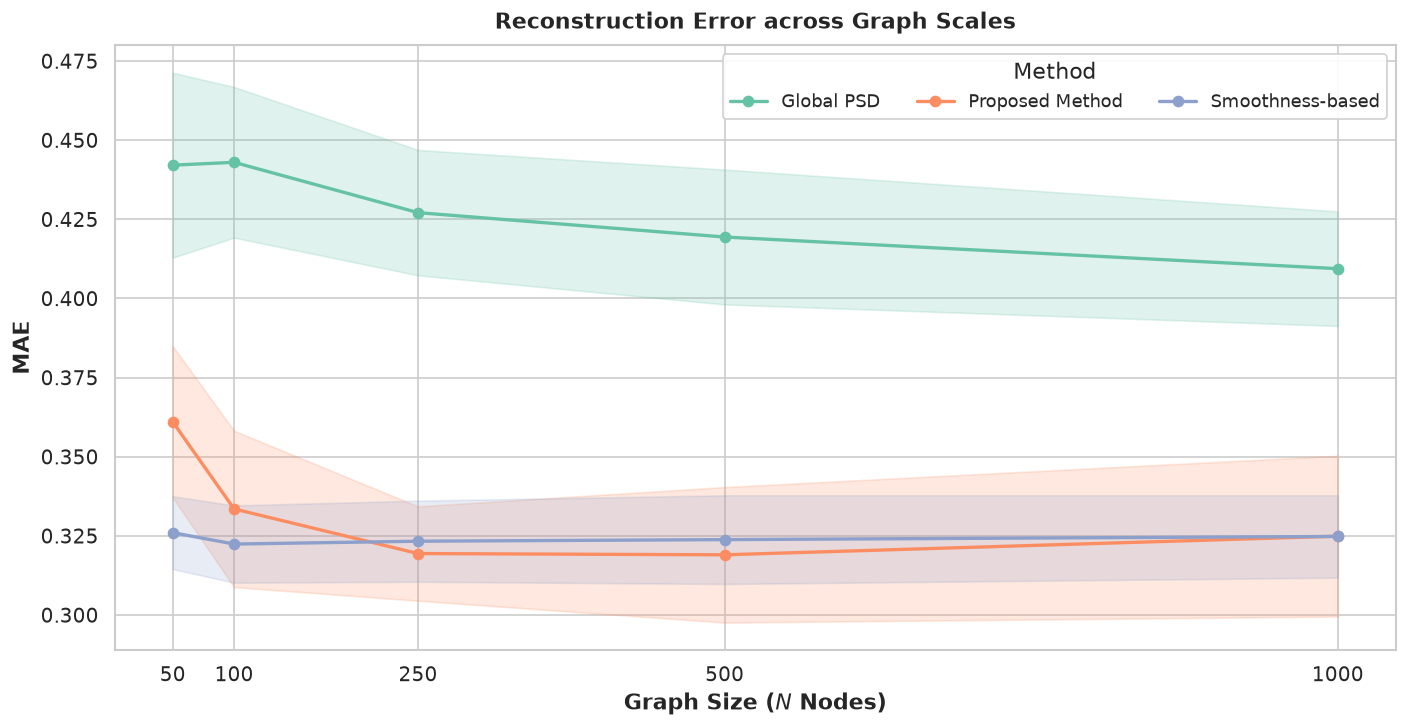

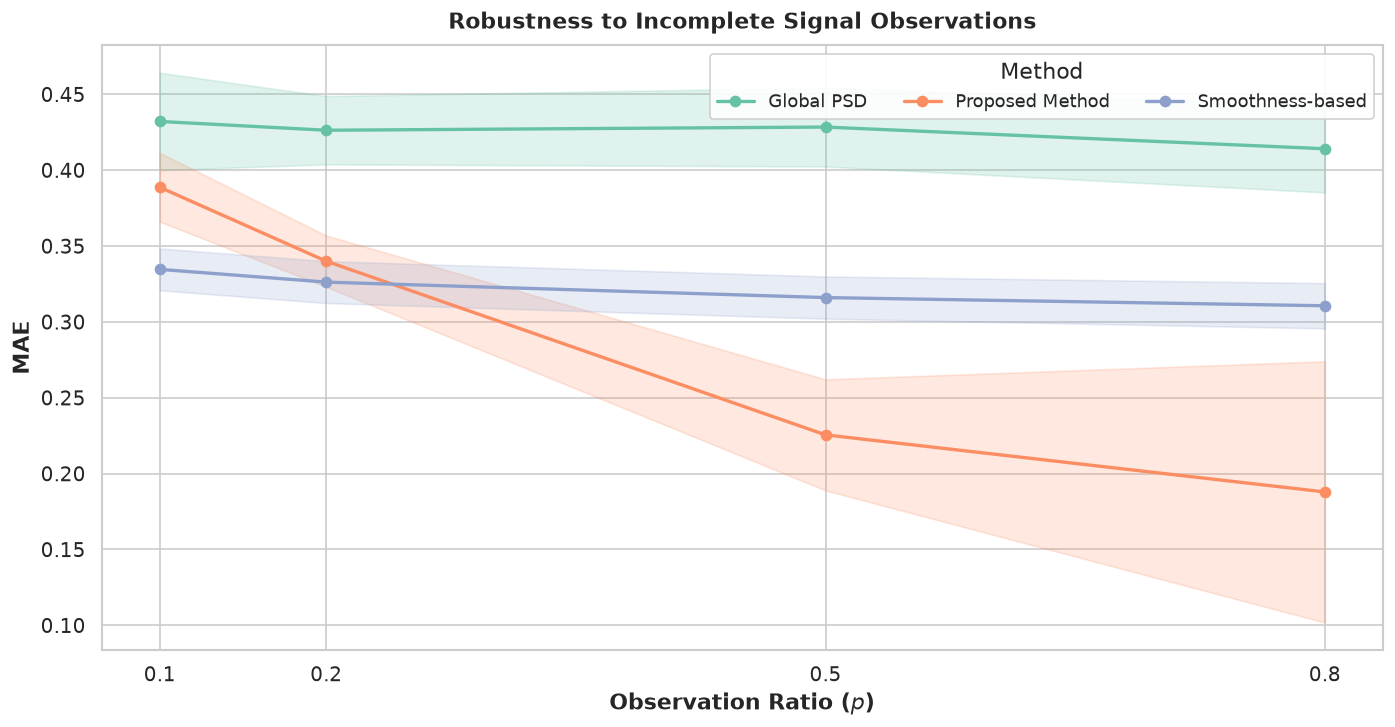

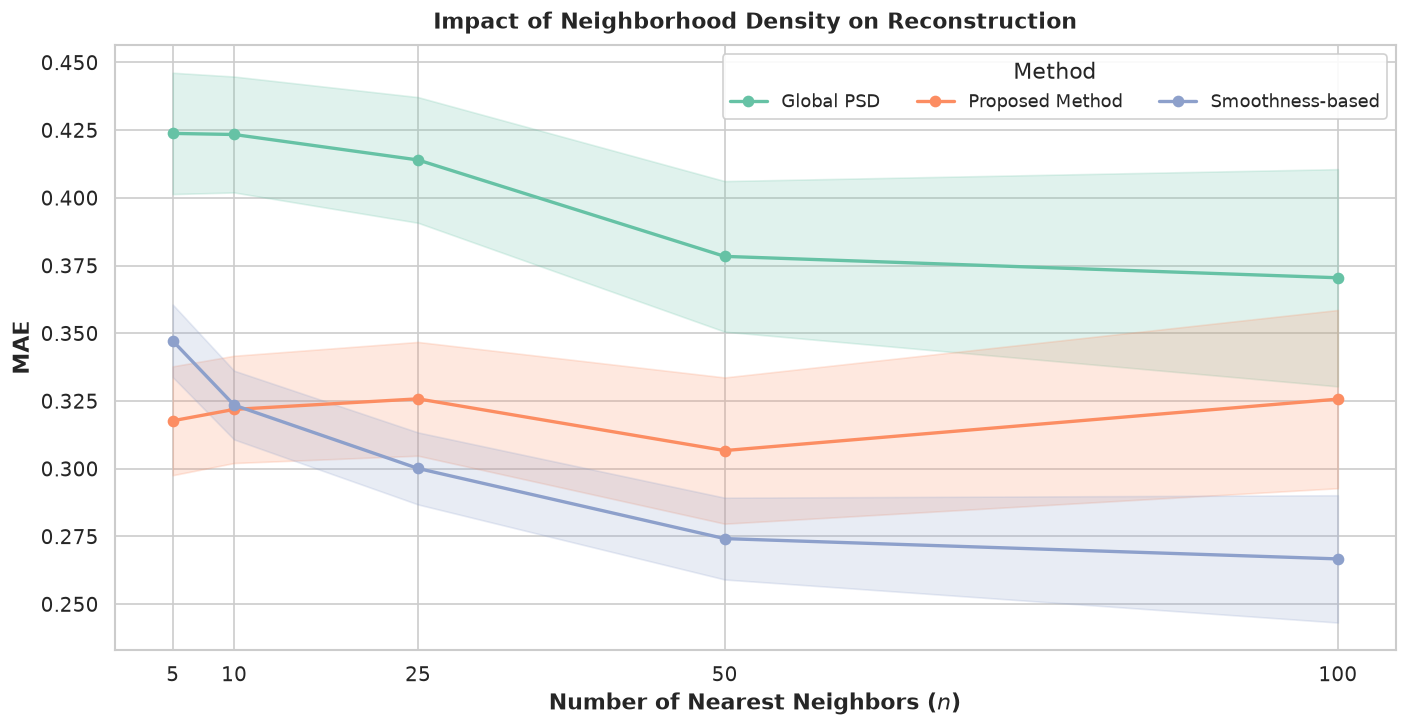

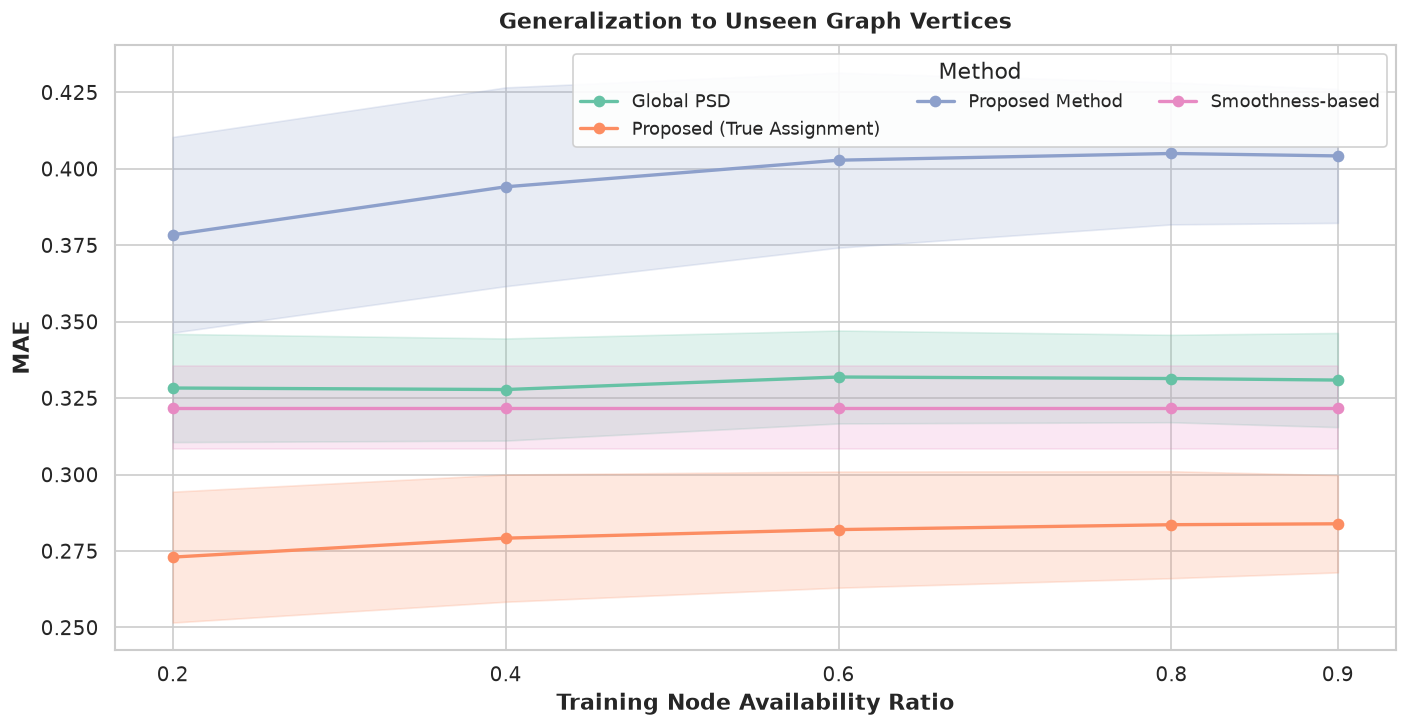

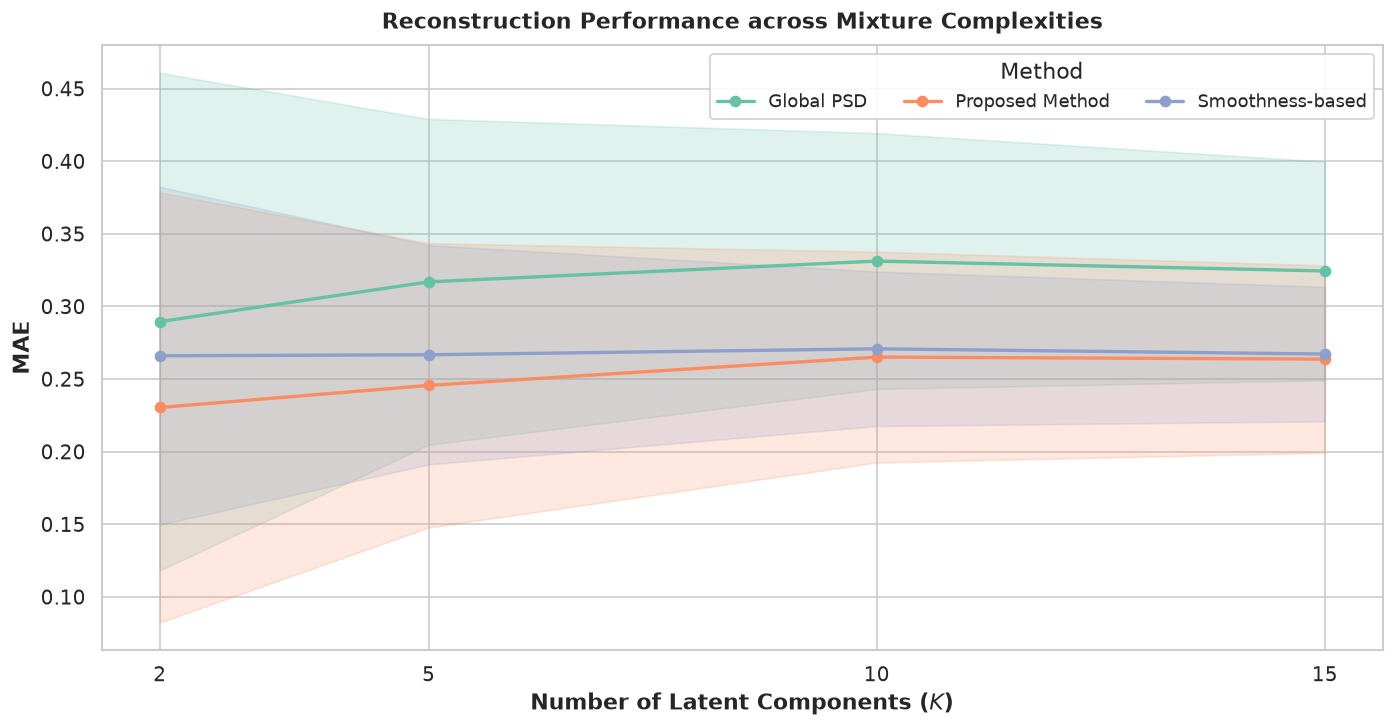

In [16]:
REC_PALETTE = "Set2"
REC_METRIC = "mae"


df_s_v_n_rec = apply_mapping(pd.read_csv(os.path.join(REC_DIR, "graph_size_visibility_neighbors_reconstruction_results.csv")))

# 1.1 Reconstruction and clustering across graph sizes
plot_line_filled(
    df_s_v_n_rec[df_s_v_n_rec['experiment'] == 'number_of_nodes'], 
    x_col='n_nodes', hue_col='method', 
    title="Reconstruction Error across Graph Scales", 
    xlabel="Graph Size ($N$ Nodes)", 
    metric=REC_METRIC, palette=REC_PALETTE
)

# 1.2 Effect of missing observations
plot_line_filled(
    df_s_v_n_rec[df_s_v_n_rec['experiment'] == 'visibility'], 
    x_col='p_observed', hue_col='method', 
    title="Robustness to Incomplete Signal Observations", 
    xlabel="Observation Ratio ($p$)", 
    metric=REC_METRIC, palette=REC_PALETTE
)

# 1.3 Effect of neighborhood size (k-NN)
plot_line_filled(
    df_s_v_n_rec[df_s_v_n_rec['experiment'] == 'k_neighbors'], 
    x_col='k_neighbors', hue_col='method', 
    title="Impact of Neighborhood Density on Reconstruction", 
    xlabel="Number of Nearest Neighbors ($n$)", 
    metric=REC_METRIC, palette=REC_PALETTE
)

# 2. Spline transfer / Transductive transferability
df_spline_rec = apply_mapping(pd.read_csv(os.path.join(REC_DIR, "spline_transfer_reconstruction_results.csv")))
plot_line_filled(
    df_spline_rec[df_spline_rec['experiment'] == 'mixed_signals'], 
    x_col='train_vertex_visibility', hue_col='method', 
    title="Generalization to Unseen Graph Vertices", 
    xlabel="Training Node Availability Ratio", 
    metric=REC_METRIC, palette=REC_PALETTE
)

# 3. Mixture complexity (multiple PSD profiles)
df_psd_rec = apply_mapping(pd.read_csv(os.path.join(REC_DIR, "multiple_psd_reconstruction_results.csv")))
plot_line_filled(
    df_psd_rec, 
    x_col='n_components', hue_col='method', 
    title="Reconstruction Performance across Mixture Complexities", 
    xlabel="Number of Latent Components ($K$)", 
    metric=REC_METRIC, palette=REC_PALETTE
)



## Reconstruction Results

Load reconstruction summaries and compare error across graph size, visibility, neighborhood size, PSD transfer, and mixture complexity.

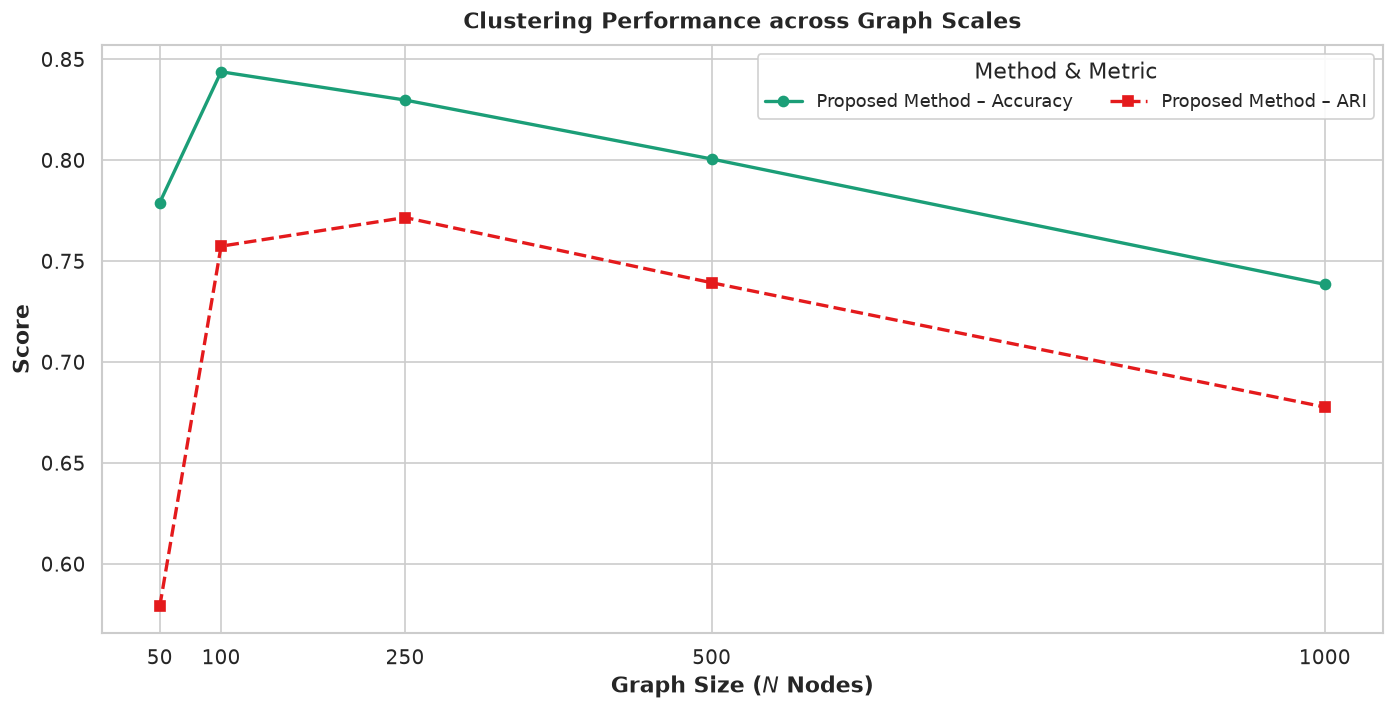

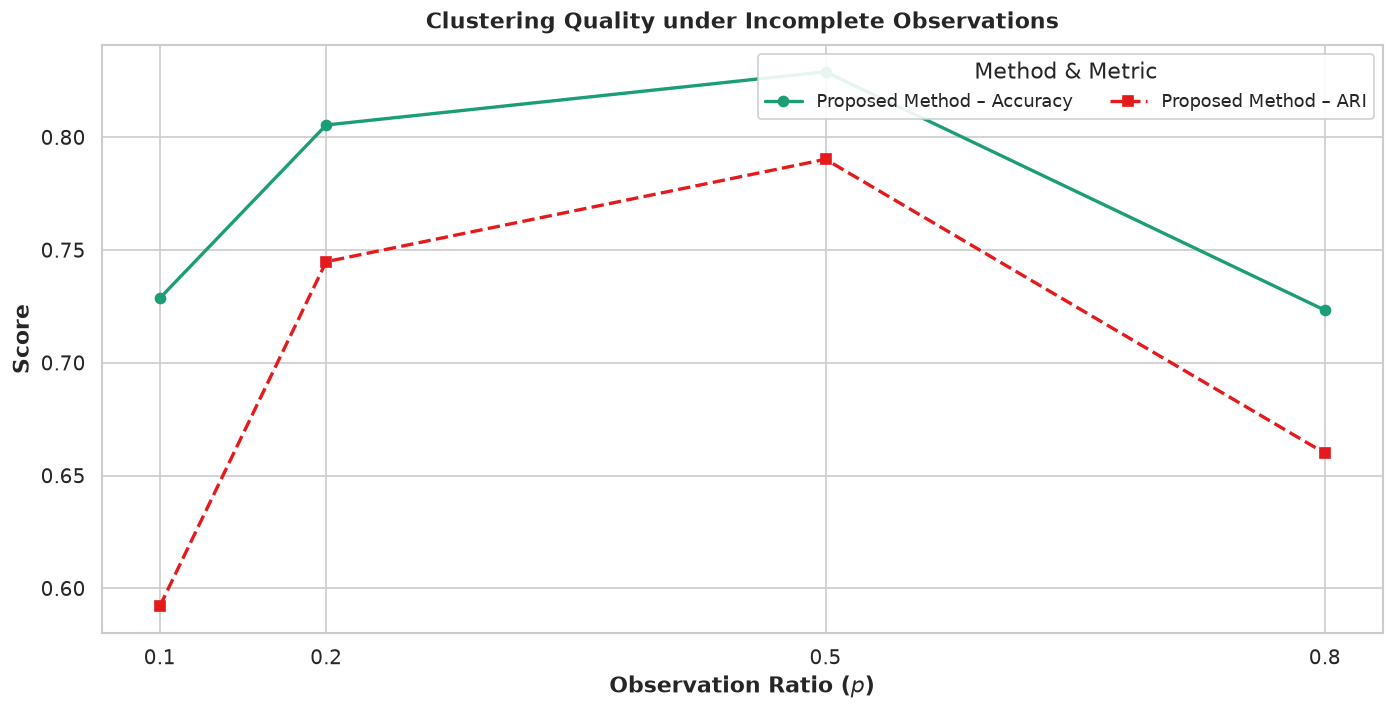

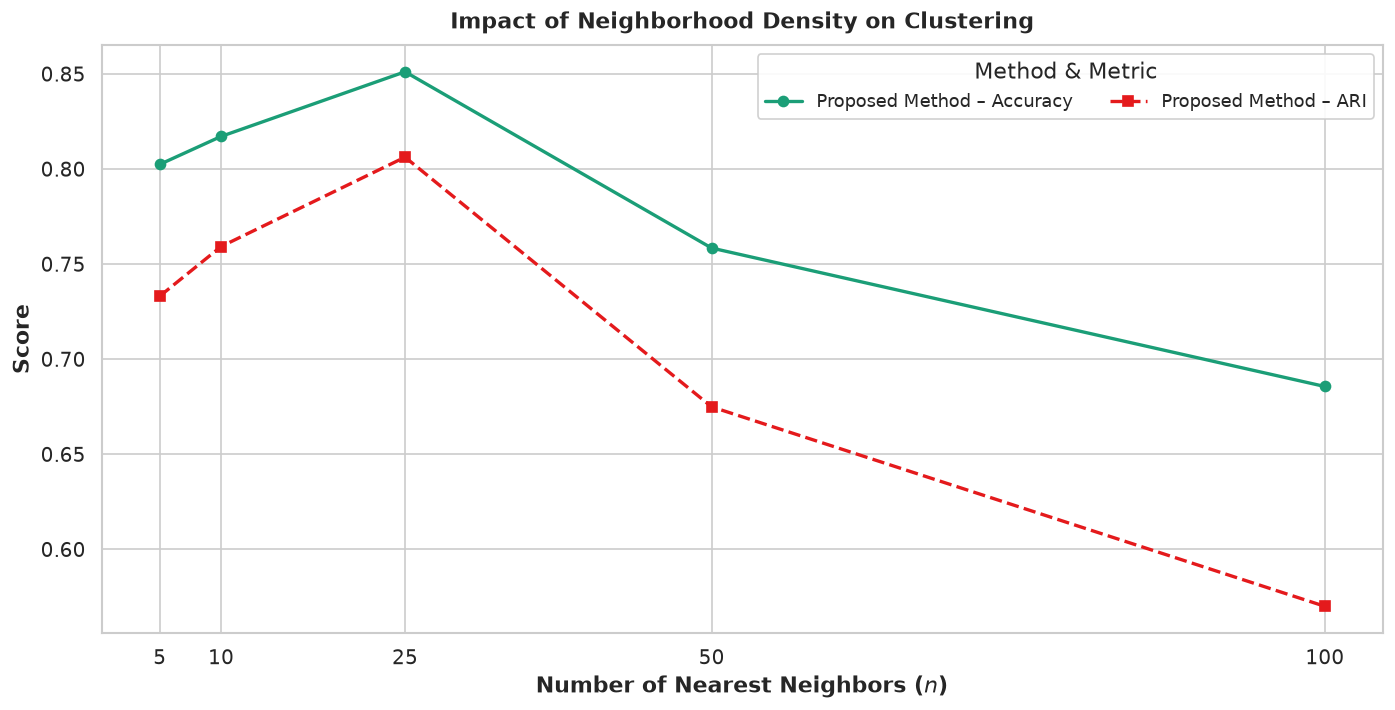

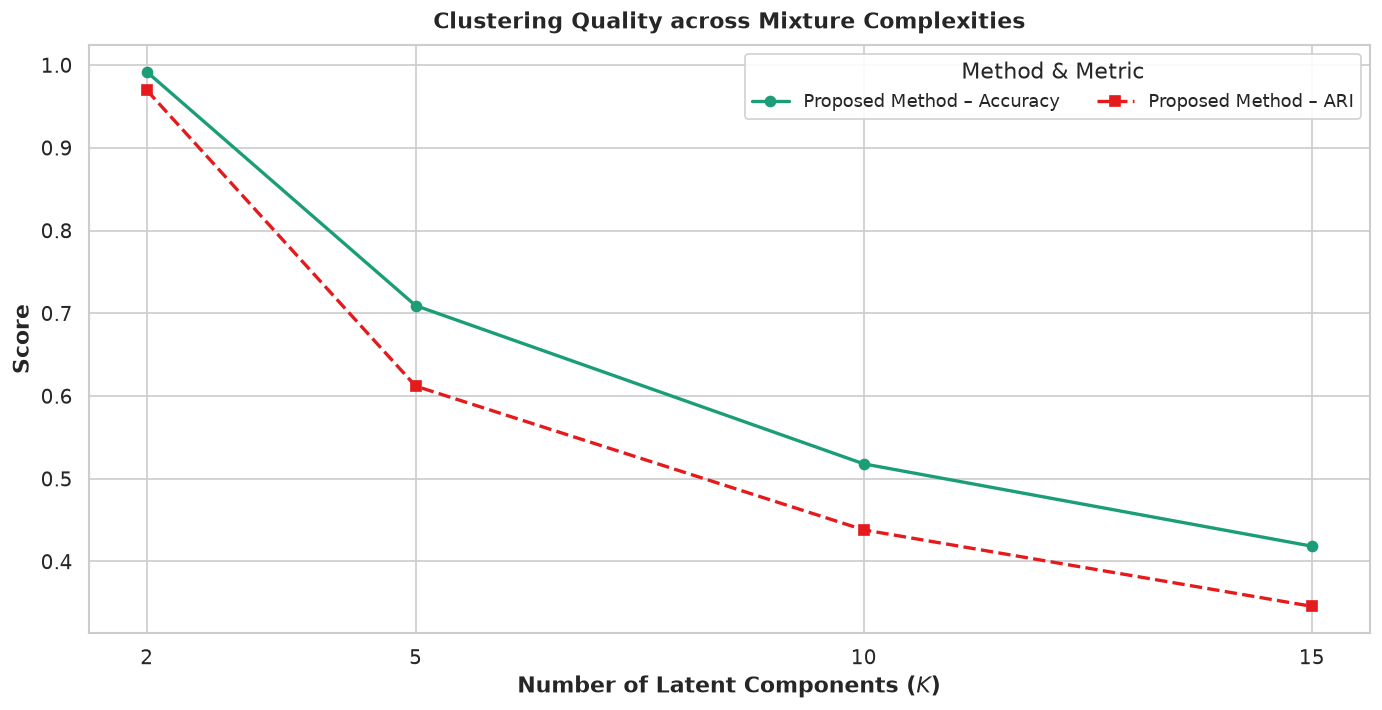

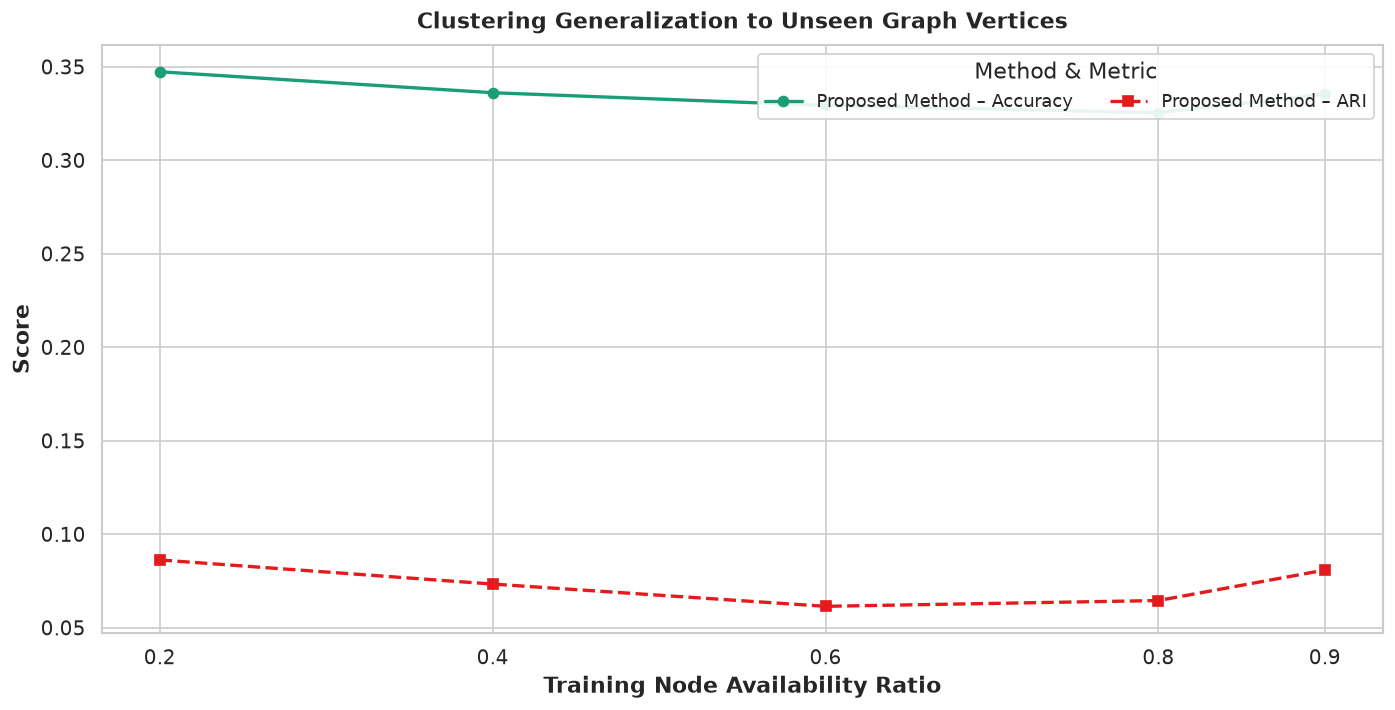

In [17]:
# Define separate palettes for Accuracy and ARI
CLUS_PAL1 = "Dark2"
CLUS_PAL2 = "Set1"

df_s_v_n_clus = apply_mapping(pd.read_csv(os.path.join(CLUS_DIR, "graph_size_visibility_neighbors_clustering_results.csv")))

# 1.1 Reconstruction and clustering across graph sizes
plot_double_line_filled(
    df_s_v_n_clus[df_s_v_n_clus['experiment'] == 'number_of_nodes'], 
    x_col='n_nodes', hue_col='method', 
    title="Clustering Performance across Graph Scales", 
    xlabel="Graph Size ($N$ Nodes)", 
    palette1=CLUS_PAL1, palette2=CLUS_PAL2
)

# 1.2 Effect of missing observations
plot_double_line_filled(
    df_s_v_n_clus[df_s_v_n_clus['experiment'] == 'visibility'], 
    x_col='p_observed', hue_col='method', 
    title="Clustering Quality under Incomplete Observations", 
    xlabel="Observation Ratio ($p$)", 
    palette1=CLUS_PAL1, palette2=CLUS_PAL2
)

# 1.3 Effect of neighborhood size (k-NN)
plot_double_line_filled(
    df_s_v_n_clus[df_s_v_n_clus['experiment'] == 'k_neighbors'], 
    x_col='k_neighbors', hue_col='method', 
    title="Impact of Neighborhood Density on Clustering", 
    xlabel="Number of Nearest Neighbors ($n$)", 
    palette1=CLUS_PAL1, palette2=CLUS_PAL2
)

# 2. Mixture complexity (multiple PSD profiles)
df_psd_clus = apply_mapping(pd.read_csv(os.path.join(CLUS_DIR, "multiple_psd_clustering_results.csv")))
plot_double_line_filled(
    df_psd_clus, 
    x_col='n_components', hue_col='method', 
    title="Clustering Quality across Mixture Complexities", 
    xlabel="Number of Latent Components ($K$)", 
    palette1=CLUS_PAL1, palette2=CLUS_PAL2
)
# 3. Spline transfer (Clustering)
df_spline_clus = apply_mapping(pd.read_csv(os.path.join(CLUS_DIR, "spline_transfer_clustering_results.csv")))

# Exclude the oracle method, which uses ground-truth labels.
df_spline_clus_filtered = df_spline_clus[
    (df_spline_clus['experiment'] == 'mixed_signals') & 
    (df_spline_clus['method'] != 'Proposed (True Assignment)')
]

plot_double_line_filled(
    df_spline_clus_filtered, 
    x_col='train_vertex_visibility', 
    hue_col='method', 
    title="Clustering Generalization to Unseen Graph Vertices", 
    xlabel="Training Node Availability Ratio", 
    palette1=CLUS_PAL1, 
    palette2=CLUS_PAL2
)

## Clustering Results

Load clustering summaries and compare ARI and clustering accuracy across the experiment settings.